# Metaspace: A Scientific Memorandum

### Formal reconstruction, coherence, and effective dimension in complex dynamical systems

**Version 8.0 — scientific edition.** Original formulation: A. Panin, manifesto v7.2 (“The Middle Way and the Edge of Harmony”). Scientific edition, numerical experiments, and text: LLM collaboration. Date: 26 October 2026.

---

**Abstract.** This memorandum turns the v7.2 manifesto into a form that can be tested: it defines the objects explicitly, separates definitions from propositions, states hypotheses together with null models, and reports numerical experiments. There are three main results. (1) The observables $K$, $S_R$, and $C$ reduce to known quantities — the Kuramoto order parameter, Shannon entropy, and quadrature capacity; in the narrow-band regime $K$ and $C$ are functionally dependent, so the “$(E,C)$ plane” is not an independent state space. (2) The $(E,C)$ dynamical system of v7.2 has no limit cycle: the divergence of the vector field is strictly negative (Dulac's criterion), and the non-trivial equilibrium is always a stable node with real negative eigenvalues; the discriminant of the characteristic polynomial is positive for all admissible parameters. (3) The “noise versus genius” criterion is replaced by a calibrated statistical decision: a naive threshold on the in-sample gain gives FDR $\approx 0.81$, whereas the Benjamini–Hochberg procedure keeps FDR $\approx 0.10$ at the same ranking quality. The memorandum also discusses necessary conditions for a limit cycle, a measurement programme, and the limits of applicability.

**Keywords:** coherence, order parameter, entropy, effective dimension, limit cycle, Dulac's criterion, multiple testing, false discovery rate.


## 0. Scope, status, and reading rules

This is **not a physical theory and not a manifesto**. It is a mathematical reconstruction: a set of definitions, several propositions with proofs, a collection of testable hypotheses, and a report on numerical experiments. Everything that cannot be reduced to these categories has been removed; the full axiom-by-axiom audit is in `docs/audit.md` (in Russian).

The text follows five rules:

1. **Every object is defined before it is used.** An operation without a definition is not an operation.
2. **Every statement has a truth value and a way to be tested.** “Axiom” is not a device for protecting a claim from testing.
3. **Every number has units, uncertainty, and a source.** Numbers without a derivation or an error bar are not used as model parameters.
4. **No eponyms without a reference.** A name is not a proof.
5. **Metaphor is allowed only as a comment**, never as an argument.

| In v7.2 | In v8 |
|---|---|
| 22 axioms, including esoteric ones | 4 definitions, 3 propositions, 5 hypotheses; the rest is removed or demoted |
| The “limit cycle” as a given | A no-cycle theorem plus necessary conditions for a cycle |
| The “edge of harmony” $\chi$ as a decision rule | A calibrated statistical test controlling FDR |
| The “Middle Way” as an attractor | A balance functional plus a control problem |
| The “quantum of dimension” $\lambda$, six spheres, $\alpha_{\text{life}}=\pi$ | Removed: no derivation, units, or mechanism |


In [1]:
import sys
import pathlib

ROOT = pathlib.Path.cwd()
while not (ROOT / "metaspace").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

from metaspace import Flow
from metaspace import experiments as ex
from metaspace.plotting import setup_style
from metaspace import (
    coherence,
    born_entropy,
    quadrature_capacity,
    participation_dimension,
    balance_functional,
    shannon_entropy,
)
from metaspace.dynamics import semi_implicit_trajectory

setup_style("en")
plt.rcParams["figure.max_open_warning"] = 0

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Project root:", ROOT)


Python: 3.13.1
NumPy: 2.3.4
Matplotlib: 3.10.8
Project root: C:\Users\afina\OneDrive\Dokumenty\deepseek-harness\default-workspace


## 1. Formal core

### 1.1 State and observables

**Definition 1.1 (state).** A state is a pair $X=(\psi,\alpha)$, where $\psi\in\mathbb{C}^N$ is a complex vector and $\alpha=a+ib\in\mathbb{C}$ is a slice parameter. The real part $a\ge 0$ is interpreted as an **effective dimension** (a measurable quantity); the imaginary part $b$ is a **parameter of analytic continuation**. The quantity $b$ is not a dimension in the topological sense: it has no metric, no measure, and no definition of dimension that would allow it to be measured independently. The word “metaspace” denotes the set of such states, not a new physical space.

**Definition 1.2 (coherence, entropy, capacity).** For $\psi\ne 0$:

$$
K(X)=\frac{\left|\sum_{i=1}^{N}\psi_i\right|}{\sum_{i=1}^{N}|\psi_i|}\in[0,1],
\qquad
p_i=\frac{|\psi_i|^2}{\sum_{j=1}^{N}|\psi_j|^2},
\qquad
S_R(X)=-\sum_{i=1}^{N}p_i\ln p_i\ge 0,
$$

$$
\bar\varphi=\arg\sum_{i=1}^{N}\psi_i,
\qquad
C(X)=\frac{\sum_{i=1}^{N}\left|\operatorname{Im}\left(e^{-i\bar\varphi}\psi_i\right)\right|^2}{\sum_{i=1}^{N}|\psi_i|^2}\in[0,1].
$$

$K$ is the weighted Kuramoto order parameter (the standard one for equal amplitudes); $S_R$ is the Shannon entropy of the Born distribution; $C$ is the normalised variance of the quadrature orthogonal to the mean phase.

**Difference from v7.2.** The manifesto used $C=\sum_i\|\operatorname{Im}\psi_i\|^2$. That quantity is not invariant under a global phase rotation $\psi\mapsto e^{i\theta}\psi$: its value depends on an arbitrary choice of phase origin. In v8 the origin is tied to the mean phase $\bar\varphi$, so $C$ is invariant under a global $U(1)$ rotation and has meaning only together with this convention.

**Definition 1.3 (effective dimension).** For a non-negative spectrum $\lambda_i$ (eigenvalues of the state operator, singular values, or mode weights),

$$
D_{\mathrm{eff}}=\frac{\left(\sum_i\lambda_i\right)^2}{\sum_i\lambda_i^2}\in[1,N].
$$

For a uniform spectrum of $N$ modes, $D_{\mathrm{eff}}=N$; for a single mode, $D_{\mathrm{eff}}=1$. This is the operational replacement for the real part of the “complex dimension”: $D_{\mathrm{eff}}$ is estimated from data and comes with a confidence interval.

**Operational status of $a$ and $b$.** In a concrete model, $a$ must be identified with a chosen dimension estimator (for example, $D_{\mathrm{eff}}$); without such an identification, $a$ is a free parameter, not an observable. Likewise, statements that depend on $b$ are testable only after a specific analytic continuation has been specified; in v8 no such statements are used, apart from the formal definition of the balance functionals. This limitation matters: “complex dimension” by itself is not a measurable quantity.

**Definition 1.4 (balance functionals).** For $N\ge 2$, a reference dimension $a_{\mathrm{ref}}\ge 0$ supplied by the problem, and $S_{\max}=\ln N$:

$$
\mu(X)=\frac{1}{5}\left[(1-K)+\frac{S_R}{S_{\max}}+C+\frac{|b|}{1+|b|}+\frac{|a-a_{\mathrm{ref}}|}{1+|a-a_{\mathrm{ref}}|}\right],
$$

$$
\nu(X)=\frac{1}{5}\left[K+\left(1-\frac{S_R}{S_{\max}}\right)+e^{-C}+\frac{1}{1+b^2}+\frac{1}{1+|a-a_{\mathrm{ref}}|}\right].
$$

Both functionals lie in $[0,1]$; $\mu$ measures incoherence and mixing, $\nu$ measures order and “absoluteness”. The balance set $\{\mu=\nu\}$ is a codimension-one surface. Unlike v7.2, there is no privileged dimension $\pi$: $a_{\mathrm{ref}}$ is fixed by the problem, not by numerology. The empirical content of Definition 1.4 depends on how $a$ and $b$ are defined; the experiment in Section 4 uses a reduced version without $a$ and $b$.


In [2]:
rng = np.random.default_rng(7)

amplitudes = rng.gamma(2.0, 0.6, 12)
psi = amplitudes * np.exp(1j * rng.normal(0.0, 0.35, 12))
K = coherence(psi)
S = born_entropy(psi)
C = quadrature_capacity(psi)
D = participation_dimension(np.abs(psi) ** 2)

print(f"K = {K:.4f}   (0 — complete decoherence, 1 — synchronization)")
print(f"S = {S:.4f} nats   (maximum ln 12 = {np.log(12):.4f})")
print(f"C = {C:.4f}   (0 — phases on one axis)")
print(f"2(1-K) = {2 * (1 - K):.4f}")
print(f"D_eff = {D:.3f}")

aligned = np.array([1.0, 2.0, 3.0])
anti = np.array([1.0, -1.0])
zero_c = np.array([1.0, -1.0, 1.0])
print(f"\nK(aligned) = {coherence(aligned):.4f}")
print(f"K(anti-phase) = {coherence(anti):.4f}")
print(f"C(aligned) = {quadrature_capacity(aligned):.4e}")
print(f"For (1,-1,1): C = {quadrature_capacity(zero_c):.1e}, K = {coherence(zero_c):.4f} "
      f"(C=0 does not imply K=1)")


K = 0.9466   (0 — complete decoherence, 1 — synchronization)
S = 2.1738 nats   (maximum ln 12 = 2.4849)
C = 0.0948   (0 — phases on one axis)
2(1-K) = 0.1067
D_eff = 7.753

K(aligned) = 1.0000
K(anti-phase) = 0.0000
C(aligned) = 0.0000e+00
For (1,-1,1): C = 0.0e+00, K = 0.3333 (C=0 does not imply K=1)


### 1.2 Propositions

**Proposition 1 (bounds on coherence).** For every $\psi\ne0$, $0\le K\le1$. The equality $K=1$ holds if and only if all non-zero components have the same phase: $\psi_i=r_i e^{i\varphi}$ with $r_i\ge0$.

*Proof.* The triangle inequality gives $|\sum_i\psi_i|\le\sum_i|\psi_i|$, hence $K\le1$. Equality requires all $\psi_i$ to be collinear as vectors in $\mathbb{C}$; for complex numbers this means a common argument. $\square$

**Proposition 2 (gauge invariance of capacity).** $C(e^{i\theta}\psi)=C(\psi)$ for every $\theta\in\mathbb{R}$. Moreover, $C=0$ if and only if all $e^{-i\bar\varphi}\psi_i$ are real, that is, the phases of the components are $\bar\varphi$ or $\bar\varphi+\pi$. In particular, $K=1\Rightarrow C=0$; the converse fails: for $\psi=(1,-1,1)$ we have $C=0$ but $K=1/3$.

*Proof.* Under $\psi\mapsto e^{i\theta}\psi$ the mean phase shifts as $\bar\varphi\mapsto\bar\varphi+\theta$, so $e^{-i\bar\varphi}\psi$ is unchanged. Next, $C=0$ means that every imaginary part of $e^{-i\bar\varphi}\psi_i$ vanishes, so every component lies on the real axis in the mean-phase frame. If all phases coincide, this holds and $K=1$; but components with phase $\bar\varphi+\pi$ also have zero imaginary part while reducing $K$. $\square$

**Proposition 3 (redundancy of $K$ and $C$ at narrow band).** Let the amplitudes be equal and the phases be $\theta_i=\varphi+\delta_i$ with independent $\delta_i\sim\mathcal{N}(0,\sigma^2)$. Then, as $N\to\infty$ and $\sigma\to0$,

$$
K=1-\frac{\sigma^2}{2}+O(\sigma^4),
\qquad
C=\sigma^2\left(1-\frac{1}{N}\right)+O(\sigma^4),
\qquad\text{and hence}\qquad
C=2(1-K)+O(\sigma^4).
$$

*Proof.* Expanding $e^{i\delta}=1+i\delta-\delta^2/2+O(\delta^3)$ gives $\mathbb{E}e^{i\delta}=1-\sigma^2/2+O(\sigma^4)$, whence $K=|\mathbb{E}e^{i\delta}|=1-\sigma^2/2+O(\sigma^4)$. Further, $\operatorname{Im}(e^{-i\bar\varphi}e^{i\theta_i})\approx\delta_i-\bar\delta$, so $C=\mathbb{E}[(\delta_i-\bar\delta)^2]+O(\sigma^4)=\sigma^2(1-1/N)+O(\sigma^4)$. $\square$

**Corollary.** $K$ and $C$ are not independent coordinates: in the narrow-band regime they determine each other up to $O(\sigma^4)$. If the variable $E$ in the v7.2 model is itself a function of $K$ (for example, $E=1-K$), then the pair $(E,C)$ is a one-dimensional curve, not a plane. This does not make the $(E,C)$ model meaningless; it means that the model cannot be declared a fundamental state space without additional justification. The entropy $S_R$ depends on the amplitude distribution and is generically independent of $K$, so the pair $(K,S_R)$ is a legitimate two-dimensional set of observables.


Max |C / 2(1-K) - 1| for sigma <= 0.2: 0.030
Ratio C / 2(1-K) at sigma = 1.0: 0.551
U(1) invariance error of C: 0.00e+00
Effective dimensions:
  single mode    1.000
  uniform 4      4.000
  exponential    3.696


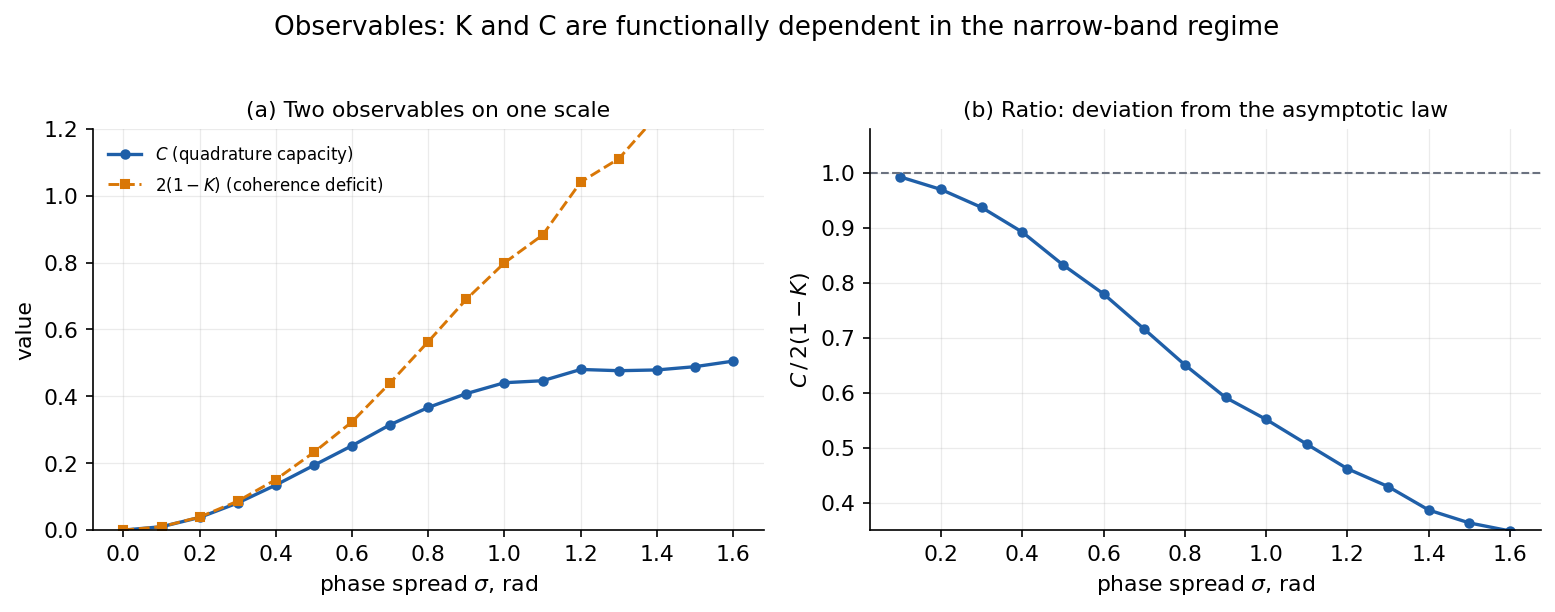

In [3]:
fig, m1 = ex.exp_observables(lang="en")
print("Max |C / 2(1-K) - 1| for sigma <= 0.2:", f"{m1['ratio_small_sigma']:.3f}")
print("Ratio C / 2(1-K) at sigma = 1.0:", f"{m1['ratio_at_sigma_1']:.3f}")
print("U(1) invariance error of C:", f"{m1['invariance_error']:.2e}")
print("Effective dimensions:")
for name, value in m1["effective_dimensions"].items():
    print(f"  {name:14s} {value:.3f}")


**Figure 1.** Left: $C$ and $2(1-K)$ as functions of the phase spread $\sigma$. The curves coincide for $\sigma\lesssim0.4$ and separate at larger $\sigma$, where the expansion of Proposition 3 fails. Right: the ratio $C/2(1-K)$; for $\sigma\le0.2$ the deviation from unity is at most 3% (including finite-$N$ error), while at $\sigma=1$ the ratio drops to about 0.55.

**What this changes.** In v7.2, $K$ and $C$ were treated as independent coordinates of a “phase space”. The experiment and Proposition 3 show that in the narrow-band regime they carry the same information in two different encodings. Independence appears only for a broad phase distribution or unequal amplitudes — and then it must be measured, not postulated.


### 1.3 Entropy: estimation and bias

$S_R$ is not a metaphysical “entropy of choice”; it is the ordinary Shannon entropy of the distribution $p_i$. Estimated from a finite sample, it is biased downward: if $m$ categories have positive probabilities,

$$
\mathbb{E}[\hat S_R]-S_R\approx-\frac{m-1}{2N}.
$$

The Miller–Madow correction

$$
\hat S_R^{\mathrm{MM}}=\hat S_R+\frac{\hat m-1}{2N},
\qquad \hat m=\#\{i:\hat p_i>0\},
$$

reduces the bias to $O(N^{-2})$ in the standard regime (fixed $m$, all categories observed with probability tending to one).

This matters for any measurement programme: without the correction, comparisons of entropy across sample sizes are systematically biased, and an apparent “growth of entropy” may be an artefact of sample size.


True entropy: 1.8381 nats
Bias at N=200: plug-in -0.0166 nats; Miller–Madow +0.0008 nats


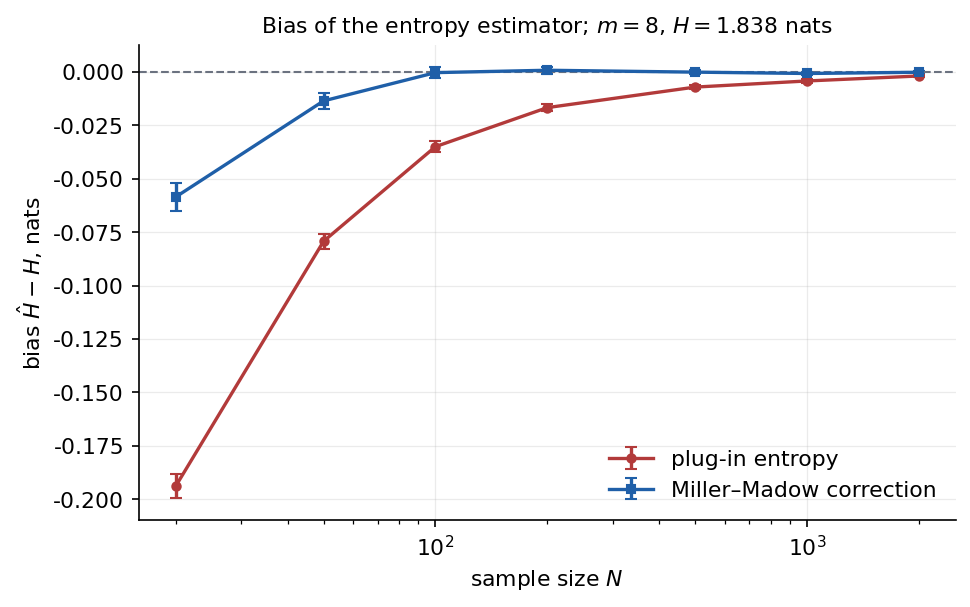

In [4]:
fig, m2 = ex.exp_entropy(lang="en")
print("True entropy:", f"{m2['H_true']:.4f} nats")
print("Bias at N=200: plug-in", f"{m2['bias_at_200_plugin']:+.4f}", "nats; Miller–Madow",
      f"{m2['bias_at_200_mm']:+.4f}", "nats")


**Figure 2.** Bias of the plug-in entropy (red circles) and of the Miller–Madow estimator (blue squares) as a function of sample size, with 95% intervals. At $N=200$ the plug-in estimate is low by about 0.017 nats; the correction reduces the bias to about 0.001 nats.

**Consequence for v7.2.** The claim “$S_R\to\max$” cannot be tested with raw sample entropies: the maximum is unreachable at finite $N$, and comparisons across samples are biased. Any statement about entropy must be formulated for a bias-corrected estimator with a confidence interval.


## 2. Dynamics of $(E,C)$: what exactly the model asserts

### 2.1 The model

Consider the reduced system of v7.2 (Section 5):

$$
\frac{dE}{da}=-AE+BC,
\qquad
\frac{dC}{da}=-\beta C+\gamma(C)E,
\qquad
\gamma(C)=\frac{\gamma_0}{1+(C/C_0)^2},
\tag{2.1}
$$

where $A,B,\beta,\gamma_0,C_0>0$ and $E,C\ge0$ are normalised “error” and “capacity”. The parameter $a$ is the real part of the dimension, that is, simply a parameter along the trajectory; time does not enter the system.

**Notation.** In Section 1, $C(X)$ is the functional of quadrature capacity; in (2.1), $C$ is a scalar dynamical variable representing capacity. This is a reduction, not an identity: below, $C$ is an independent model variable, not a state functional.

In v7.2 it was asserted that (2.1) has a limit cycle. The results below show that this is not the case — and cannot be the case for any admissible parameters.


### 2.2 Theorem 1: there are no periodic orbits

**Theorem 1 (Dulac).** Let $A,B,\beta,\gamma_0,C_0>0$ and $\gamma'(C)\le0$ for $C\ge0$. Then system (2.1) has no closed orbits in the closed first quadrant $E\ge0$, $C\ge0$.

*Proof.* Take the Dulac function $g(E,C)\equiv1$. The divergence of the field is

$$
\nabla\cdot(gF)=\frac{\partial}{\partial E}(-AE+BC)+\frac{\partial}{\partial C}\left(-\beta C+\gamma(C)E\right)
=-A-\beta+E\gamma'(C)\le-(A+\beta)<0.
$$

If a closed orbit bounded a region $\Omega$, then by the divergence theorem

$$
0=\oint_{\partial\Omega}F\cdot n\,ds=\int_\Omega\nabla\cdot F\,dA<0,
$$

a contradiction. $\square$

**Boundedness and the $\omega$-limit.** In the canonical regime, trajectories remain in a compact region: for large $E$ the derivative $\dot E$ is negative, and the region where both derivatives are positive is bounded by the cubic decay $\gamma(C)\sim C^{-2}$. Numerical checks for the canonical parameters confirm this. For arbitrary admissible parameters, boundedness is an additional condition that must be checked separately; without it, the Poincaré–Bendixson theorem does not apply. When boundedness holds, the $\omega$-limit set consists of equilibria or closed orbits; by Theorem 1 there are no closed orbits, so the limit set is an equilibrium.


### 2.3 Theorem 2: the equilibrium is always a stable node

**Theorem 2.** Let $u=\gamma_0B/(A\beta)-1>0$. Then (2.1) has a unique interior equilibrium

$$
C^*=C_0\sqrt{u},
\qquad
E^*=\frac{B}{A}C^*,
$$

and this equilibrium is a stable node: the eigenvalues of the Jacobian are real and negative.

*Proof.* Setting the right-hand sides to zero gives $C=(A/B)E$ and $\beta C=\gamma(C)E$. Substituting the first into the second yields $\gamma(C^*)=A\beta/B$, whence $u=(\gamma_0B/(A\beta))-1=(C^*/C_0)^2$ and the formulas for $C^*,E^*$ follow.

The Jacobian at the equilibrium is

$$
J=\begin{pmatrix}-A & B\\ \gamma(C^*) & -\beta+E^*\gamma'(C^*)\end{pmatrix}.
$$

Let $x=-E^*\gamma'(C^*)>0$ (since $\gamma'<0$). Then

$$
\operatorname{tr}J=-(A+\beta)-x<0,
\qquad
\det J= A x>0,
$$

$$
\Delta=(\operatorname{tr}J)^2-4\det J=(A-x)^2+2\beta(A+x)+\beta^2>0.
$$

The last expression is positive for all $A,\beta,x>0$. Hence both eigenvalues are real; their sum is negative and their product is positive, so both are negative. $\square$

**Explicit formula.** From $u=(C^*/C_0)^2$ and $\gamma(C^*)=A\beta/B$,

$$
x=-E^*\gamma'(C^*)=\frac{2\beta u}{1+u}\in(0,2\beta).
$$

Therefore $\operatorname{tr}J<-(A+\beta)$, and $\Delta=(A-x)^2+2\beta(A+x)+\beta^2>0$ for all $A,\beta,x>0$; the conclusion does not depend on the particular value of $u$.

**Corollary 1.** There is no limit cycle; moreover, there are no damped oscillations either, because the eigenvalues are real. The system relaxes to a node without oscillation.

**Corollary 2.** A stochastic “quasi-cycle” interpretation is also impossible in the linear approximation: for a stable node with real eigenvalues, the power spectral density has no interior maximum. Any observed oscillation in such a model requires external periodic forcing or a structural change of the equations.

**Projection.** In v7.2, $\chi$ does not enter the right-hand sides of (2.1). Therefore any deterministic cycle in the extended space $(E,C,\chi)$ would project to a closed orbit of (2.1), which does not exist by Theorem 1. The stochastic dynamics of $\chi$ may produce random fluctuations, but not a limit cycle.


Equilibrium: E* = 1.224745, C* = 1.224745
Eigenvalues: [-2.76619 -0.43381]
tr J = -3.2000  det J = 1.2000  Delta = 5.4400
Numerical convergence rate: 0.4443
max div on [0,4]^2: -2.0000
min Delta over the parameter grid: 4.3265
rho(J_map): min = 0.3457  max = 0.9957
Semi-implicit scheme stable on the tested range: True


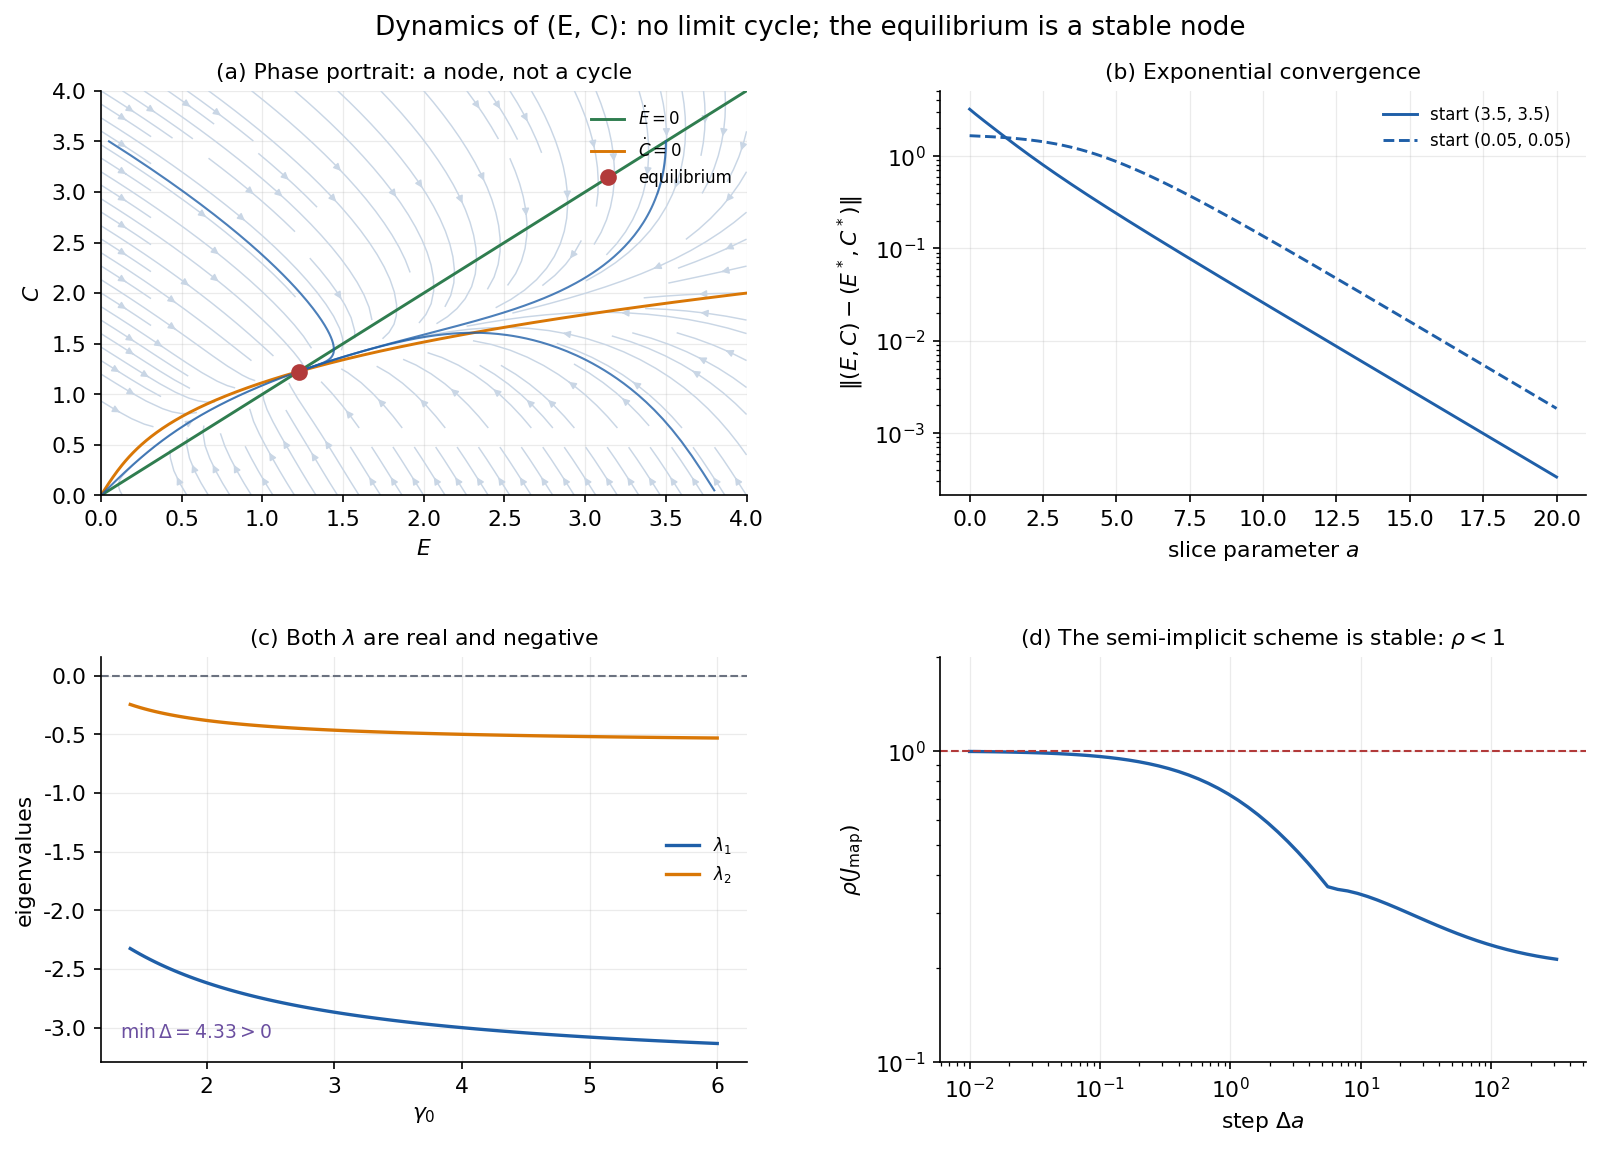

In [5]:
flow = Flow()
fig, m3 = ex.exp_dynamics(flow, lang="en")
print("Equilibrium:", f"E* = {m3['fixed_point'][0]:.6f}, C* = {m3['fixed_point'][1]:.6f}")
print("Eigenvalues:", np.round(m3["eigenvalues"], 6))
print("tr J =", f"{m3['trace']:.4f}", " det J =", f"{m3['det']:.4f}", " Delta =", f"{m3['disc']:.4f}")
print("Numerical convergence rate:", f"{m3['convergence_rate']:.4f}")
print("max div on [0,4]^2:", f"{m3['max_divergence_on_grid']:.4f}")
print("min Delta over the parameter grid:", f"{m3['min_discriminant_on_grid']:.4f}")
print("rho(J_map): min =", f"{m3['min_map_radius']:.4f}", " max =", f"{m3['max_map_radius']:.4f}")
print("Semi-implicit scheme stable on the tested range:", m3["map_stable_for_all_tested_deltas"])


**Figure 3.** (a) Phase portrait: all trajectories converge to the node $(1.2247,1.2247)$; coloured lines are nullclines. (b) Exponential convergence: the slope on the semi-log plot corresponds to a rate of about 0.44, close to $|\lambda_{\max}|=0.434$. (c) Eigenvalues as functions of $\gamma_0$: both are real and negative, and the discriminant is positive everywhere ($\min\Delta=4.33$). (d) Spectral radius of the Jacobian of the semi-implicit scheme, $\rho<1$ on the whole tested range $10^{-2}\le\Delta a\le10^{2.5}$.

**Interpretation.** The v7.2 claim of a limit cycle is not supported: there is no cycle in the continuous system and none in its standard discretisation. The stronger result is that the equilibrium is always a node, so the model does not even exhibit oscillatory transients. This is not a “negative result about a special case” but a structural property of class (2.1) with $\gamma'\le0$.


### 2.4 Discretisation does not create a cycle

The v7.2 scheme is

$$
E_{n+1}=\frac{E_n+\Delta a\,B C_n}{1+A\Delta a},
\qquad
C_{n+1}=\frac{C_n+\Delta a\,\gamma(C_n)E_{n+1}}{1+\beta_1\Delta a}.
\tag{2.2}
$$

Its fixed point coincides with the equilibrium of (2.1). The spectral radius of the map's Jacobian at the equilibrium, $\rho(\Delta a)$, determines local stability. Numerically, $\rho<1$ on the whole range $10^{-2}\le\Delta a\le10^{2.5}$; moreover, $\rho\to1$ as $\Delta a\to0$ (as expected for a first-order scheme) and $\rho$ decreases with the step. Hence the “cyclicity” claimed in v7.2 is not explained by a discretisation artefact at the canonical parameters either.

**Caveat.** For extreme, physically inadmissible parameters the scheme can lose stability: for example, with $A=0.118$, $B=7.316$, $\beta=5.86$, $\gamma_0=6.311$, $C_0=0.2$, $\Delta a=1.288$, iteration (2.2) reaches a period-2 orbit with $E\approx270$–$300$, which corresponds to an “error” larger than one and lies outside the normalised domain. This does not rehabilitate the cycle; it shows why any reproduction must report $\rho$ and the parameter range.


In [6]:
extreme = Flow(A=0.118, B=7.316, beta=5.86, gamma0=6.311, C0=0.2)
trajectory = semi_implicit_trajectory(extreme, 1.288, n_steps=20000)
last = trajectory[-1000:]
print("rho(J_map) =", f"{extreme.map_spectral_radius(1.288):.3f}", "(> 1: local instability)")
print("E over the last 1000 iterations: min =", f"{last[:, 0].min():.2f}",
      ", max =", f"{last[:, 0].max():.2f}")
print("Last 4 E values:", np.round(trajectory[-4:, 0], 2))
print("Last 4 C values:", np.round(trajectory[-4:, 1], 2))


rho(J_map) = 1.548 (> 1: local instability)
E over the last 1000 iterations: min = 269.53 , max = 299.95
Last 4 E values: [299.95 269.53 299.95 269.53]
Last 4 C values: [1.12 8.07 1.12 8.07]


### 2.5 What would be needed for a limit cycle

For a two-dimensional autonomous system, the standard route to a cycle is a Hopf bifurcation; it requires

$$
\operatorname{tr}J=0,
\qquad
\det J>0
$$

at some point. In class (2.1) with $\gamma'\le0$, $\operatorname{tr}J<-(A+\beta)<0$ at the equilibrium, so a Hopf bifurcation is impossible. A structural change is needed. The minimal options are:

1. **Antagonistic coupling.** Make one of the terms negative (capacity suppresses error, error stimulates capacity). Complex eigenvalues and a stable focus then become possible; a cycle requires a loss of stability, that is, positive feedback or delay.
2. **Delay.** The model

$$
\dot E=-AE-BC(a-\tau)+S,
\qquad
\dot C=-\beta C+\gamma E
\tag{2.3}
$$

has the characteristic equation

$$
(\lambda+A)(\lambda+\beta)+B\gamma e^{-\lambda\tau}=0.
$$

Substituting $\lambda=i\omega$ gives the Hopf condition $B\gamma>A\beta$ and the frequency

$$
\omega^2=\frac{-(A^2+\beta^2)+\sqrt{(A^2+\beta^2)^2-4(A^2\beta^2-B^2\gamma^2)}}{2},
$$

while the critical delay $\tau_c$ follows from the phase condition

$$
\cos(\omega\tau)=\frac{\omega^2-A\beta}{B\gamma},
\qquad
\sin(\omega\tau)=\frac{\omega(A+\beta)}{B\gamma}>0.
$$

The linear model (2.3) produces growing oscillations when $B\gamma>A\beta$ and $\tau>\tau_c$; a stable limit cycle requires a nonlinearity that bounds the amplitude. That is a separate hypothesis about a mechanism, not a consequence of v7.2.

3. **Autocatalysis.** A positive diagonal contribution (for example, a term $\delta EC$ in the equation for $E$, or $\delta C^2$ in the equation for $C$) can make $\operatorname{tr}J$ positive. But then one must separately check that an equilibrium exists, that stability is actually lost, and that a nonlinearity bounds the amplitude; a positive diagonal term by itself guarantees nothing.

**Conclusion.** The limit cycle of v7.2 is not a result of the model but a presumed possibility. To turn it into a scientific claim, one must specify a mechanism (delay, antagonism, autocatalysis), measure its parameters, and show that the system actually lies in the corresponding regime. Without that, the “limit cycle” is an unsupported interpretation.


## 3. From the $\chi$ heuristic to calibrated detection

### 3.1 The detection problem

Suppose there are $n$ observations and $p$ candidate features. For each feature $j$ we compute the in-sample gain $R^2_{\mathrm{in},j}$ (for example, the increase in explained variance when the feature is added). The task is to decide which features are substantive and which are noise.

In v7.2 this was done with the index

$$
\chi(X)=\frac{\mu(X)}{\nu(X)}\cdot\frac{1-\langle\cos\Delta\phi\rangle_{\text{env}}}{1+|\Delta\alpha|/\lambda},
$$

and a “dynamic” threshold $\chi_{\text{crit}}$. This rule has no null distribution: $\chi$ has no probabilistic model, and the threshold controls no frequency error. Hence “a genius outlier” and “parasitic imaginarity” are not statistically distinguishable categories — they are labels for the same event: a large in-sample gain.

### 3.2 What can be measured

For a selected set $S$:

$$
\text{precision}=\frac{TP}{|S|},
\qquad
\text{recall}=\frac{TP}{k},
\qquad
\text{FDR}=\mathbb{E}\left[\frac{FP}{|S|}\right],
$$

where $k$ is the number of true features (known in simulation, unknown in a real problem). In addition, the out-of-sample gain $R^2_{\mathrm{out}}$ measures whether the effect transfers to new data.

Three procedures are compared:

* **Naive threshold (top-$m$):** select the $m$ features with the largest $R^2_{\mathrm{in}}$. The error rate is uncontrolled.
* **Benjamini–Hochberg (BH):** use $p$-values and the step-up procedure at level $q$; it controls FDR under independence or positive dependence (PRDS).
* **Permutation maximum:** simulate the distribution of $\max_j R^2_{\mathrm{in}}$ under random label permutations and take its $1-\alpha$ quantile; it controls the family-wise error rate.

### 3.3 Experiment

Parameters: $n=100$, $p=200$, $k=2$ true features with effect $0.45$, 1000 replications, naive budget $m=10$, $q=0.1$, 500 permutations.


Naive top-10 precision=0.195 recall=0.975 FDR=0.805 R2_out=-0.022 AUC=0.994
BH, q=0.1 precision=0.896 recall=0.754 FDR=0.097 R2_out=+0.111 AUC=0.994

Top-10 threshold: 0.035
95% null quantile: 0.129
Winner's curse: mean R2_in = 0.188 , mean R2_out = 0.129


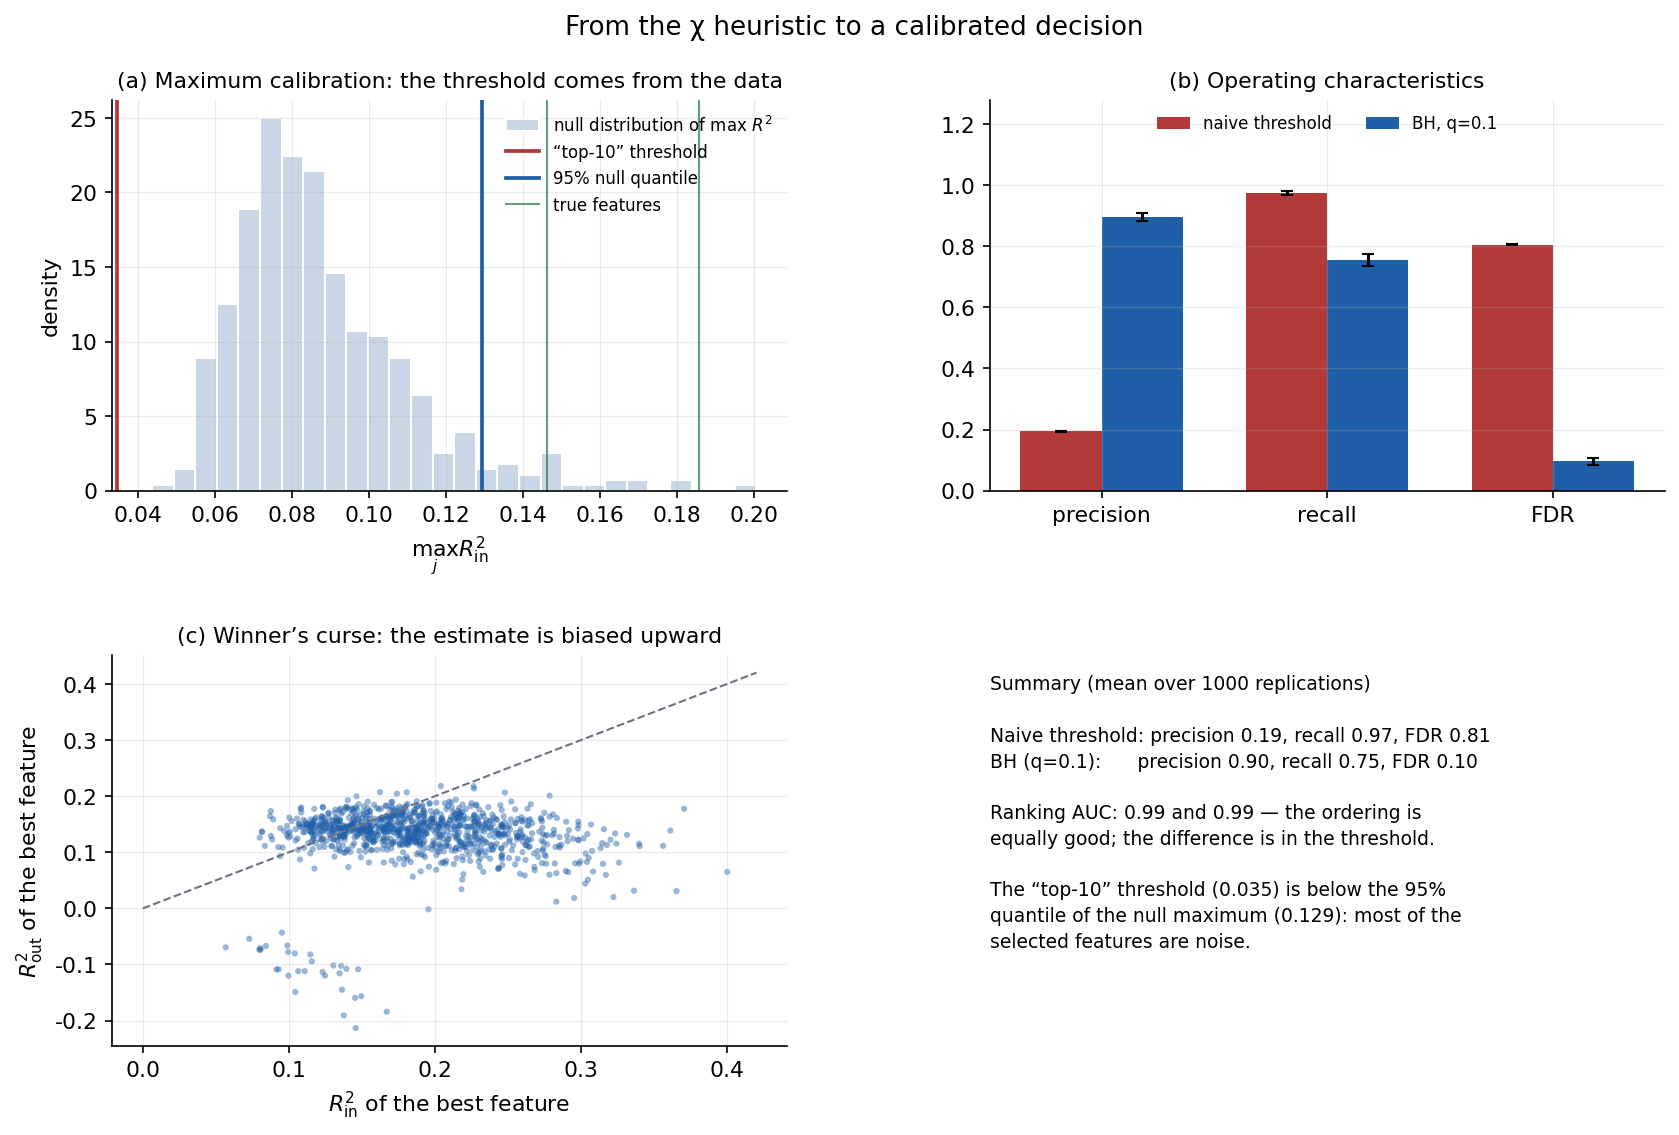

In [7]:
fig, m5 = ex.exp_detection(reps=1000, n_perm=500, lang="en")
for key, label in (("raw_top", "Naive top-10"), ("bh", "BH, q=0.1")):
    mm = m5["metrics"][key]
    print(label, f"precision={mm['precision']:.3f}", f"recall={mm['recall']:.3f}",
          f"FDR={mm['fdr']:.3f}", f"R2_out={mm['mean_out_of_sample_r2']:+.3f}",
          f"AUC={mm['auc']:.3f}")
print("\nTop-10 threshold:", f"{m5['example']['raw_cut']:.3f}")
print("95% null quantile:", f"{m5['example']['null_q95']:.3f}")
print("Winner's curse: mean R2_in =", f"{m5['winner']['in_sample'].mean():.3f}",
      ", mean R2_out =", f"{m5['winner']['out_of_sample'].mean():.3f}")


**Figure 4.** (a) Null distribution of the maximum $R^2_{\mathrm{in}}$ under label permutation (500 permutations), its 95% quantile (blue line), the naive top-10 threshold (red line), and the scores of the true features (green lines). The naive threshold lies below the null quantile: most features it selects are noise. (b) Precision, recall, and FDR for the naive threshold and BH, with 95% intervals. (c) In-sample gain of the best feature against its out-of-sample gain: points lie mostly below the diagonal, so the estimate is biased upward.

**Results.** Naive threshold: precision $0.20$, recall $0.97$, FDR $0.81$, $R^2_{\mathrm{out}}=-0.02$. BH: precision $0.90$, recall $0.75$, FDR $0.10$, $R^2_{\mathrm{out}}=+0.11$. The ranking AUC is $\approx0.99$ in both cases: **the ordering by in-sample gain is good; the problem is the threshold.** This is why replacing the “magic” $\chi_{\text{crit}}$ with a calibrated threshold helps without changing the ranking.

**Consequence for Axiom 22.** “Genius” is not a separate ontological category that can be recognised by $\chi$. It is a small effect that (i) survives calibration, (ii) replicates on new data, and (iii) comes with a reported effect size and confidence interval. The naive threshold systematically confuses noise with signal; a calibrated procedure controls the false discovery rate but does not guarantee that every individual discovery is true. A universal guarantee to “preserve genius for every finite $n$” does not exist: it is a direct consequence of the no-free-lunch principle in statistics.

**Caveat.** The experiment does not compute $\chi$ literally: it models the key property of the $\chi$-gate — selection by in-sample gain without a null distribution. A direct test of $\chi$ requires data with known ground truth and is left for the field stage (H3).


## 4. The Middle Way as a control problem

### 4.1 The balance functional

In the reduced $(E,C)$ model define

$$
\mu(E,C)=\frac12\left[\frac{E}{1+E}+\frac{C}{1+C}\right],
\qquad
\nu(E,C)=\frac12\left[\frac{1}{1+E}+\frac{1}{1+C}\right].
$$

Then $\mu+\nu=1$ and

$$
\mu-\nu=\frac{EC-1}{(1+E)(1+C)}.
$$

The balance set $\{\mu=\nu\}$ is the hyperbola $EC=1$. This is the two-dimensional version of the same idea as Definition 1.4: codimension one, not a point and not an attractor.

### 4.2 Unforced dynamics

For (2.1) the equilibrium has $E^*C^*=(1.2247)^2=1.5$, so it lies off the balance set: $\mu-\nu\approx0.10$. A trajectory from $(0.05,0.05)$ crosses $EC=1$ exactly once and then moves to the equilibrium. Balance is a **transient event**, not a state the system seeks.

### 4.3 Control

Adding a control input $u$ to the equation for $E$ gives

$$
\frac{d(EC)}{da}=C(-AE+BC+u)+E(-\beta C+\gamma(C)E).
$$

The choice

$$
u=\frac{-k(EC-1)+(A+\beta)EC-BC^2-\gamma(C)E^2}{C}
$$

(for $C>0$) yields $\frac{d(EC)}{da}=-k(EC-1)$, so $EC\to1$ exponentially. This is not a “law of nature” but a demonstration: balance is attainable if the system has the appropriate feedback. Whether a particular system has it is an empirical question.


Equilibrium: E*C* = 1.5000 , balance gap = 0.1010
Crossings of EC=1 without control: 1
Crossings of EC=1 with control: 0
Final EC with control: 1.000000
Final |EC-1| with control: 5.33e-15


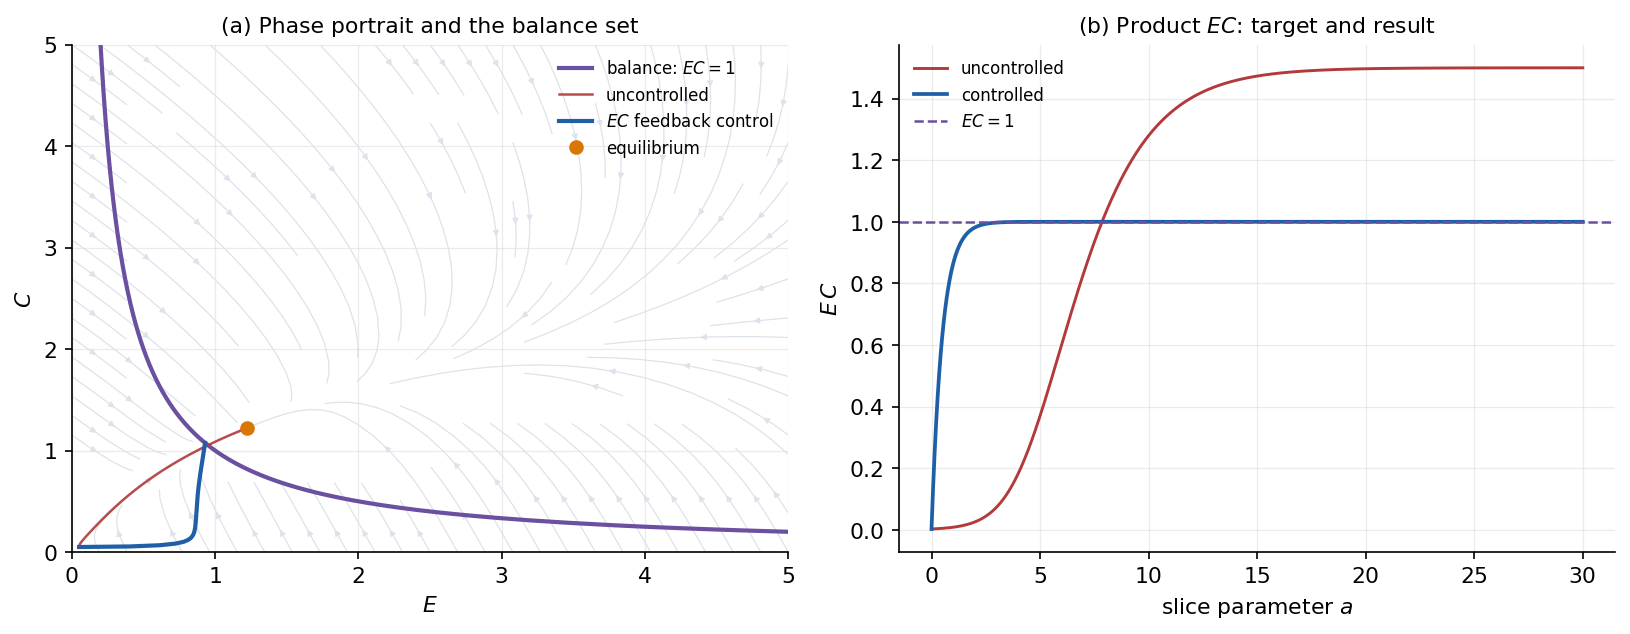

In [8]:
flow = Flow()
fig, m4 = ex.exp_balance(flow, lang="en")
print("Equilibrium: E*C* =", f"{m4['equilibrium_product']:.4f}",
      ", balance gap =", f"{m4['equilibrium_gap']:.4f}")
print("Crossings of EC=1 without control:", m4["uncontrolled_crossings"])
print("Crossings of EC=1 with control:", m4["controlled_crossings"])
print("Final EC with control:", f"{m4['controlled_final_product']:.6f}")
print("Final |EC-1| with control:", f"{m4['controlled_final_abs_gap']:.2e}")


**Figure 5.** (a) Phase portrait, the balance hyperbola $EC=1$, the free trajectory (red), and the trajectory with feedback (blue); the equilibrium of the free system lies off the hyperbola. (b) The product $EC$ along the trajectories: the free system passes through 1 and moves to 1.5; the controlled system reaches 1 and stays there.

**Consequence for Axiom 21.** The claim “the Middle Way is an attractor” is false in the reduced model: balance is crossed transversally and is not maintained. The correct formulation is: **balance is a target set that can be stabilised by control.** A testable hypothesis is that a particular system possesses feedback that keeps $\mu\approx\nu$; it must be formulated as a question about residence time in a neighbourhood of $\{\mu=\nu\}$ and about the response to perturbations, not as an axiom.


## 5. Hypotheses and falsification criteria

The table lists the minimal set of claims that can be tested and, in principle, refuted. For each hypothesis we give a prediction, a null model, and the current status.

| ID | Hypothesis | Prediction | Null model / test | Status |
|---|---|---|---|---|
| **H1** | Class (2.1) with $A,B,\beta>0$ and $\gamma'\le0$ has no sustained oscillations | The power spectral density has no interior maximum (linear approximation); no quasi-cycle peak | Spectral test: AR(2) with real roots versus complex roots; Theorems 1–2 | Supported analytically and numerically |
| **H2** | $K$ and $C$ are redundant at narrow band | $C/2(1-K)\to1$ as $\sigma\to0$; deviation $<5\%$ for $\sigma<0.3$ | Monte Carlo over $\sigma$; Proposition 3 | Supported |
| **H3** | The naive $\chi$-threshold does not control FDR | $\mathrm{FDR}_{\text{naive}}>0.5$ while $\mathrm{FDR}_{\text{BH}}\le0.15$ | Regression proxy experiment (Section 3) | Supported on the proxy; field-data test needed |
| **H4** | The balance set is not an attractor of the free system | Finite number of crossings; no convergence $\mu-\nu\to0$ | Direct integration of (2.1); crossing count | Supported in the reduced model |
| **H5** | Coherence regularisation improves the robustness of a complex-valued classifier to phase noise | Higher accuracy under phase noise than a baseline with the same number of parameters | Pre-registered experiment: phase-coded task, real-valued baseline, 20 seeds | Planned |

**What these hypotheses do not claim.** They do not claim that “metaspace” exists as physical reality, that dimension can be complex in the sense of a metric space, or that coherence is a universal currency of nature. They claim only that the listed quantities are measurable and that the listed relations are testable.

**Stopping rule.** An experiment stops not when “$\langle\chi\rangle$ stabilises on a limit cycle” but when a pre-specified precision of the effect estimate is reached and FDR is controlled. This rule is reproducible and independent of interpretation.


## 6. What was removed and why

The full audit of the 22 axioms, the 7 “theorems”, and the sections on algebra, topology, calculus, and applications is in `docs/audit.md` (Russian). Here is a summary by category.

| Element of v7.2 | Status in v8 | Reason |
|---|---|---|
| “Quantum of dimension” $\lambda=0.020203236\ldots$, six spheres (7,6,5,4,3,2 forms) | Removed | No derivation, units, uncertainty, or independent measurement; the numbers do not follow from the model |
| $\alpha_{\text{life}}=\pi$ | Removed | $\pi$ is not a dimension; no mechanism explains why life would require this value |
| Division by zero $X\oslash\mathbf{0}_{\mathfrak{M}}$ | Removed | The operation is undefined; “raising the dimension” does not follow from mathematics. The real analogue is renormalisation and the anomalous dimension $d_{\mathrm{eff}}=d+\gamma$, which is computed |
| “Imaginary zero” $\mathbf{0}_{\text{imag}}$, $\mathbf{1}_{\text{imag}}^2=-\mathbf{1}$ | Removed | $\mathbb{C}$ is standard and $i^2=-1$ needs no new axiom; the “imaginary zero” is undefined, and its consistency cannot be checked without specifying the operation. For nilpotent objects there is Grassmann algebra ($\theta^2=0$, $\theta_i\theta_j=-\theta_j\theta_i$), but it does not follow from “imaginarity” |
| Supersymmetry with superpartners | Removed as physics | No predictions or particles; only a $\mathbb{Z}_2$-grading remains as a mathematical analogy |
| Auto-imaginarity (for every $X$ there is $\varphi_X$) | Removed | Tautological: $\varphi_X=\mathrm{id}$ satisfies it; the statement carries no information |
| “Poincaré–Perelman theorem”, “Fermat theorem for $\mathfrak{M}$” | Removed | Not formulated as mathematical statements: no space, operation, quantifiers, or proof |
| Algebra $\oplus,\otimes,\circledast,\oslash$; group $\mathcal{G}_{\mathfrak{M}}$ | Removed / not used | The operations are undefined on a common carrier; the inverse formula is not checked as an inverse. Standard operations on $\mathbb{C}^N$ suffice for v8 |
| Topology: components $\mathcal{C}_0,\mathcal{C}_{\mathrm{IV}},\mathcal{C}_{\mathrm{III}},\mathcal{C}_{\mathrm{II}}$; $\pi_1=\mathbb{Z}\oplus\mathbb{Z}_2$ | Removed | No definitions, maps, or proofs; the fundamental-group claim is not testable |
| Fractional derivative of complex order; “differentiation raises dimension” | Removed | The Grünwald–Letnikov formula is defined for real order; complex order needs a separate definition. Differentiation does not raise dimension |
| Applications: fusion, string theory, “dark matter” | Removed | No calculations, units, or testable predictions; not scientific hypotheses in their current form |
| Anti-second law | Demoted | False as a universal statement (decoherence increases $S_R$ and decreases $K$); replaced by an entropy balance for an open system |
| Poincaré recurrence | Reformulated | Applies to conservative systems of finite measure; model (2.1) is dissipative, so recurrence is not guaranteed |
| Philosophical quotations | Removed from the scientific text | They are not testable statements; they may remain in a popular exposition |

**What is retained.** The definitions of $K$, $S_R$, and $C$; the idea of a complex parameter $\alpha=a+ib$ as an effective dimension plus an analytic-continuation parameter; the hierarchy of function spaces as a mathematical construction; the balance functionals; and $\chi$ as a starting heuristic (not as a decision rule).

**Audit counts.** Of the 22 axioms, 5 are retained as definitions or constructions, 4 are reformulated or restricted, 4 are demoted to hypotheses or tasks, and 9 are removed. Of the 7 “theorems”, none retains the status of a theorem in its original form; two are replaced by correct statements (Theorems 1–2 above), and the rest are removed.


## 7. Reproducibility and research programme

**Environment.** Python $\ge3.11$, `numpy`, `scipy`, `matplotlib`. The full list is in `requirements.txt`; install the package with `pip install -e .`.

**Commands.**

```bash
python experiments/run_all.py          # all figures and results/metrics.json
python tests/test_core.py              # 16 tests, no pytest required
python tools/build_notebook.py         # rebuild the Russian notebook
python tools/build_notebook_en.py      # rebuild this notebook
python tools/build_notebook_zh.py      # rebuild the Chinese notebook
```

**Data and seeds.** All experiments are deterministic: E1 — `seed=0`, E2 — `seed=0`, E3/E4 — deterministic, E5 — `seed=1`. The numbers in the text correspond to `results/metrics.json`; they are recomputed when parameters change.

**Runtime.** A full notebook run takes a few seconds; the detection experiment (1000 replications, 500 permutations) takes about 4 s.

**Structure.**

```
metaspace/                 # library: observables, dynamics, balance, statistics
experiments/run_all.py
tests/test_core.py
tools/build_notebook.py    # Russian edition
tools/build_notebook_en.py # English edition
tools/build_notebook_zh.py # Chinese edition
notebooks/metaspace_v8.ipynb
notebooks/metaspace_v8_en.ipynb
notebooks/metaspace_v8_zh.ipynb
results/figures/
results/metrics.json
docs/audit.md
```

**Programme.**

* *Theory (0–6 months).* Classify two- and three-dimensional extensions of (2.1) by the sign structure of the Jacobian; study global stability beyond $\gamma'\le0$; derive Hopf conditions for delay and antagonism; separate mechanism from curve fitting. Publish the structural negative result (Theorems 1–2) as a standalone paper.
* *Measurement (6–12 months).* Implement estimators of $K$, $S_R$, $C$, and $D_{\mathrm{eff}}$ with confidence intervals and bias corrections; pre-register tests of H1–H4 on real data (phase time series, complex-valued networks, oscillator synchronisation); publish code and data.
* *Applications (12–18 months).* Test H5 on a phase-coded complex-valued perceptron against a real-valued baseline; test whether weight coherence predicts generalisation; if not, publish the negative result. Evaluate whether balance regularisation helps; if not, close the direction.

**Success criterion** is not “harmony” but a set of reproducible, falsifiable claims with controlled error rates. **Failure criterion** is a return to statements that cannot be tested.

**Limitation.** All numerical results are obtained on synthetic data. They test mathematical statements and statistical procedures; they are not empirical confirmation of “metaspace”.


## 8. References

1. Kuramoto, Y. (1984). *Chemical Oscillations, Waves, and Turbulence*. Springer.
2. Strogatz, S. H. (2000). From Kuramoto to Crawford: exploring the onset of synchronization in populations of coupled oscillators. *Physica D*, 143(1–4), 1–20.
3. Shannon, C. E. (1948). A mathematical theory of communication. *Bell System Technical Journal*, 27(3), 379–423.
4. Miller, G. A. (1955). Note on the bias of information estimates. In *Information Theory in Psychology* (pp. 95–100). Free Press.
5. Benjamini, Y., & Hochberg, Y. (1995). Controlling the false discovery rate: a practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society: Series B*, 57(1), 289–300.
6. Burnham, K. P., & Anderson, D. R. (2002). *Model Selection and Multimodel Inference* (2nd ed.). Springer.
7. Perko, L. (2001). *Differential Equations and Dynamical Systems* (3rd ed.). Springer.
8. Hale, J. K., & Lunel, S. M. V. (1993). *Introduction to Functional Differential Equations*. Springer.
9. Guckenheimer, J., & Holmes, P. (1983). *Nonlinear Oscillations, Dynamical Systems, and Bifurcations of Vector Fields*. Springer.
10. Prigogine, I. (1967). *Thermodynamics of Irreversible Processes* (3rd ed.). Wiley.
11. Cover, T. M., & Thomas, J. A. (2006). *Elements of Information Theory* (2nd ed.). Wiley.
12. MacKay, D. J. C. (2003). *Information Theory, Inference, and Learning Algorithms*. Cambridge University Press.
13. Ioannidis, J. P. A. (2005). Why most published research findings are false. *PLoS Medicine*, 2(8), e124.


## Appendix. Audit summary

The full table “axiom → verdict → justification” is in [`docs/audit.md`](../docs/audit.md) (Russian). Summary: 5 of the 22 axioms are retained as definitions or constructions, 4 are reformulated and restricted, 4 are demoted to hypotheses or tasks, and 9 are removed as undefined or unfalsifiable. Of the 7 “theorems”, none retains its original status; two are replaced by correct statements (Theorems 1–2 above), and the rest are removed.

---

*End of memorandum. Version 8.0.*


In [9]:
print("Key numbers")
print("-" * 62)
rows = [
    ("equilibrium E*", f"{m3['fixed_point'][0]:.6f}"),
    ("equilibrium C*", f"{m3['fixed_point'][1]:.6f}"),
    ("lambda_1", f"{m3['eigenvalues'][0]:.6f}"),
    ("lambda_2", f"{m3['eigenvalues'][1]:.6f}"),
    ("discriminant", f"{m3['disc']:.4f}"),
    ("max divergence on [0,4]^2", f"{m3['max_divergence_on_grid']:.4f}"),
    ("min Delta over gamma_0", f"{m3['min_discriminant_on_grid']:.4f}"),
    ("naive gate FDR", f"{m5['metrics']['raw_top']['fdr']:.3f}"),
    ("BH FDR", f"{m5['metrics']['bh']['fdr']:.3f}"),
    ("BH precision", f"{m5['metrics']['bh']['precision']:.3f}"),
    ("BH recall", f"{m5['metrics']['bh']['recall']:.3f}"),
    ("equilibrium EC", f"{m4['equilibrium_product']:.4f}"),
    ("|EC-1| with control", f"{m4['controlled_final_abs_gap']:.1e}"),
]
for label, value in rows:
    print(f"{label:28s} {value}")


Key numbers
--------------------------------------------------------------
equilibrium E*               1.224745
equilibrium C*               1.224745
lambda_1                     -2.766190
lambda_2                     -0.433810
discriminant                 5.4400
max divergence on [0,4]^2    -2.0000
min Delta over gamma_0       4.3265
naive gate FDR               0.805
BH FDR                       0.097
BH precision                 0.896
BH recall                    0.754
equilibrium EC               1.5000
|EC-1| with control          5.3e-15
